# C06c — Adaptive camouflage on NS10: 20 exposed / 34 held out

Retrain the C05 classifier on **unchanged regular RAID training data + 20 randomly selected NS10 AI examples**, with unit sample weights. Evaluate both adapted and original frozen detectors on the same remaining 34 NS10 texts.

The 14 selected Ghostbuster coordinates and original training normalization stay fixed. The logistic classifiers and their five-fold sigmoid calibration are refitted; symbolic feature search is not repeated. This tests adaptation within the existing representation, not a complete feature-search rerun.

No generation, language-model scoring, or subject-specific human prose is used. Human feature vectors are used for evaluation. Detector-specific thresholds come only from validation humans; test humans measure realized FPR, weighted to the held-out 34's genre mixture. All checkpoints are atomic. Rerunning resumes from the saved split/model. Run this notebook independently in the existing project environment.

In [1]:
from pathlib import Path
import os, json, hashlib, tempfile, warnings
import dill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.metrics import roc_curve, auc
from IPython.display import display

ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()), None)
assert ROOT is not None, 'Run from the reproduction project or its experiments directory.'
C05 = ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR = ROOT/'results/causal/C06b_NEW_steps5_10_v1'
META = ROOT/'results/causal/C02d2_fz118_ghostbuster_raid/fz118_paired_features.parquet'
OUT = ROOT/'results/causal/C06c_NS10_adaptive_Ghostbuster_20_34_v1'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 20260921

def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def atomic_bytes(path, data):
    path = Path(path)
    fd, tmp = tempfile.mkstemp(dir=path.parent, prefix=path.name+'.', suffix='.tmp')
    try:
        with os.fdopen(fd, 'wb') as f:
            f.write(data); f.flush(); os.fsync(f.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp): os.unlink(tmp)
def save_csv(df, path): atomic_bytes(path, df.to_csv(index=False).encode())
def save_json(obj, path): atomic_bytes(path, json.dumps(obj, indent=2, sort_keys=True).encode())
print('Output:', OUT)


Output: ../results/causal/C06c_NS10_adaptive_Ghostbuster_20_34_v1


In [2]:
NAMES = json.loads((C05/'feature_names.json').read_text())
mu = np.load(C05/'mu.npy'); sigma = np.load(C05/'sigma.npy')
assert len(NAMES) == 14 and mu.shape == sigma.shape == (14,)
assert np.isfinite(mu).all() and np.isfinite(sigma).all() and (sigma > 0).all()
with (C05/'ghostbuster_frozen.pkl').open('rb') as f: frozen = dill.load(f)
assert list(frozen.classes_) == [0, 1]

def norm(frame):
    x = frame[NAMES].to_numpy(float)
    assert np.isfinite(x).all()
    return (x-mu)/sigma

ns = pd.read_csv(NSDIR/'NS10_features.csv').sort_values('case_id').reset_index(drop=True)
texts = pd.read_csv(NSDIR/'NS10_texts.csv', keep_default_na=False).set_index('case_id')
scores = pd.read_csv(NSDIR/'NS10_scores.csv').set_index('case_id')
assert len(ns) == len(texts) == len(scores) == 54 and ns.case_id.is_unique
assert ns.source_id.is_unique and texts.index.is_unique and scores.index.is_unique
for column in ['source_id', 'domain', 'text_sha']:
    assert ns[column].tolist() == texts.loc[ns.case_id,column].tolist()
    assert ns[column].tolist() == scores.loc[ns.case_id,column].tolist()
assert [hashlib.sha256(t.encode()).hexdigest() for t in texts.loc[ns.case_id,'text']] == ns.text_sha.tolist()
Zns = norm(ns)
np.testing.assert_allclose(frozen.predict_proba(Zns)[:,1], scores.loc[ns.case_id,'AI_score'], rtol=1e-7, atol=1e-9)

meta = pd.read_parquet(META)
raid = meta.loc[meta.dataset.eq('raid'), ['source_id','split','label','domain']].reset_index(drop=True)
assert raid.source_id.is_unique
rf = pd.read_parquet(C05/'raid_all_features.parquet').set_index('doc_key')
assert rf.index.is_unique
rf = rf.loc['raid::'+raid.source_id.astype(str)].reset_index()
Zraid = norm(rf)
train = raid.split.eq('train').to_numpy()
assert set(ns.source_id).isdisjoint(raid.loc[train,'source_id'])
assert raid.set_index('source_id').loc[ns.source_id,'label'].eq(1).all()
assert raid.set_index('source_id').loc[ns.source_id,'split'].eq('test').all()
print('Verified all 54 NS10 scores and input identities against frozen C05.')


Verified all 54 NS10 scores and input identities against frozen C05.


In [3]:
# Hash inputs before persisting the fixed split/model. Changed inputs cannot silently resume.
inputs = [META] + [C05/p for p in ['ghostbuster_frozen.pkl','mu.npy','sigma.npy',
    'feature_names.json','contract.json','raid_all_features.parquet']] + [NSDIR/p for p in
    ['NS10_features.csv','NS10_scores.csv','NS10_texts.csv']]
contract = dict(version='C06c_v1', seed=SEED, adaptation_n=20, heldout_n=34,
    fit='regular RAID train plus 20 NS10 positives, unit weights; clone frozen classifier',
    representation='frozen C05 14 coordinates and mu/sigma; no new symbolic search',
    thresholds='each detector calibrated separately on same validation humans; strict score > threshold',
    sklearn=sklearn.__version__, numpy=np.__version__,
    inputs={str(p.relative_to(ROOT)):sha(p) for p in inputs})
cp = OUT/'contract.json'
if cp.exists():
    assert json.loads(cp.read_text()) == contract, 'Contract changed; use a new output directory.'
else: save_json(contract, cp)

rng = np.random.default_rng(SEED)
adapt_idx = np.sort(rng.choice(54, size=20, replace=False))
split = ns[['case_id','source_id','domain','text_sha']].copy()
split['role'] = 'heldout'; split.loc[adapt_idx,'role'] = 'adaptation'
sp = OUT/'adaptive_split_20_34.csv'
if sp.exists():
    pd.testing.assert_frame_equal(pd.read_csv(sp), split)
else: save_csv(split, sp)
held_idx = np.flatnonzero(split.role.eq('heldout').to_numpy())
assert len(held_idx)==34 and set(held_idx).isdisjoint(adapt_idx)
held = ns.iloc[held_idx].reset_index(drop=True)
display(pd.crosstab(split.domain, split.role))
display(split.loc[split.role.eq('adaptation'), ['case_id','domain']])


role,adaptation,heldout
domain,,
abstracts,1,9
books,3,4
news,3,9
recipes,6,3
reddit,3,3
reviews,0,1
wiki,4,5


,case_id,domain
2,gate_0004,recipes
4,gate_0007,wiki
8,gate_0018,recipes
9,gate_0019,reddit
11,gate_0021,wiki
13,gate_0023,books
19,gate_0030,news
21,gate_0037,recipes
22,gate_0038,reddit
25,gate_0047,books


In [4]:
Xfit = np.vstack([Zraid[train], Zns[adapt_idx]])
yfit = np.r_[raid.loc[train,'label'].to_numpy(int), np.ones(20, dtype=int)]
model_path = OUT/'ghostbuster_adapted_20.pkl'
if model_path.exists():
    with model_path.open('rb') as f: adapted = dill.load(f)
    print('Loaded saved adapted detector.')
else:
    adapted = clone(frozen)
    print(f'Fitting on {int(train.sum())} RAID training examples + 20 NS10 examples...', flush=True)
    with warnings.catch_warnings():
        warnings.filterwarnings('error', category=sklearn.exceptions.ConvergenceWarning)
        adapted.fit(Xfit, yfit)
    atomic_bytes(model_path, dill.dumps(adapted))
    print('Adapted model saved.')
assert list(adapted.classes_) == [0,1]
training_manifest = raid.loc[train,['source_id','domain','label']].copy()
training_manifest['origin']='regular_RAID_train'
extra = ns.iloc[adapt_idx][['source_id','domain']].copy()
extra['label']=1; extra['origin']='NS10_adaptation'
save_csv(pd.concat([training_manifest,extra],ignore_index=True), OUT/'training_manifest.csv')


Fitting on 1272 RAID training examples + 20 NS10 examples...


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Adapted model saved.


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  w

In [5]:
# Human weights match the held-out 34, not the full 54 cohort.
mix = held.domain.value_counts(normalize=True)
def reference(split_name):
    mask = (raid.split.eq(split_name)&raid.label.eq(0)&raid.domain.isin(mix.index)).to_numpy()
    domains = raid.loc[mask,'domain']
    counts = domains.value_counts()
    assert set(mix.index).issubset(counts.index)
    weights = np.array([mix[d]/counts[d] for d in domains])
    assert np.isclose(weights.sum(),1)
    return mask, weights
cm, wc = reference('validation'); hm, wh = reference('test')

def weighted_auc(human, ai):
    y=np.r_[np.zeros(len(human)),np.ones(len(ai))]
    w=np.r_[wh,np.ones(len(ai))/len(ai)]
    fpr,tpr,_=roc_curve(y,np.r_[human,ai],sample_weight=w,drop_intermediate=False)
    return auc(fpr,tpr)
def staircase(cal, human, ai):
    cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
    return pd.DataFrame(dict(threshold=cuts,
        calibration_FPR=[wc[cal>c].sum() for c in cuts],
        test_FPR=[wh[human>c].sum() for c in cuts],
        TPR=[(ai>c).mean() for c in cuts]))

curves={}; rows=[]; case_scores=held[['case_id','source_id','domain']].copy()
for name, model in [('Frozen',frozen),('Adapted',adapted)]:
    cal=model.predict_proba(Zraid[cm])[:,1]
    human=model.predict_proba(Zraid[hm])[:,1]
    ai=model.predict_proba(Zns[held_idx])[:,1]
    curves[name]=staircase(cal,human,ai)
    save_csv(curves[name], OUT/f'{name.lower()}_TPR_staircase.csv')
    case_scores[name+'_AI_score']=ai
    for tag, mask, weights, values in [('validation',cm,wc,cal),('test',hm,wh,human)]:
        ref=raid.loc[mask,['source_id','domain']].copy()
        ref['weight']=weights;ref['AI_score']=values
        save_csv(ref, OUT/f'{name.lower()}_{tag}_human_scores.csv')
    rows.append(dict(detector=name,heldout_cases=len(ai),AUROC=weighted_auc(human,ai),
        mean_AI_score=ai.mean(),median_AI_score=np.median(ai)))
summary=pd.DataFrame(rows)
summary['AUROC_change_vs_frozen']=summary.AUROC-summary.iloc[0].AUROC
case_scores['score_change']=case_scores.Adapted_AI_score-case_scores.Frozen_AI_score
save_csv(summary,OUT/'adaptive_camouflage_summary.csv')
save_csv(case_scores,OUT/'heldout34_scores.csv')
display(summary.round(6))
print('Important: this frozen AUROC uses only the held-out 34; it can differ from the earlier 54-case result.')


,detector,heldout_cases,AUROC,mean_AI_score,median_AI_score,AUROC_change_vs_frozen
0,Frozen,34,0.459875,0.227968,0.154963,0.000000
1,Adapted,34,0.540521,0.303047,0.222271,0.080647


Important: this frozen AUROC uses only the held-out 34; it can differ from the earlier 54-case result.


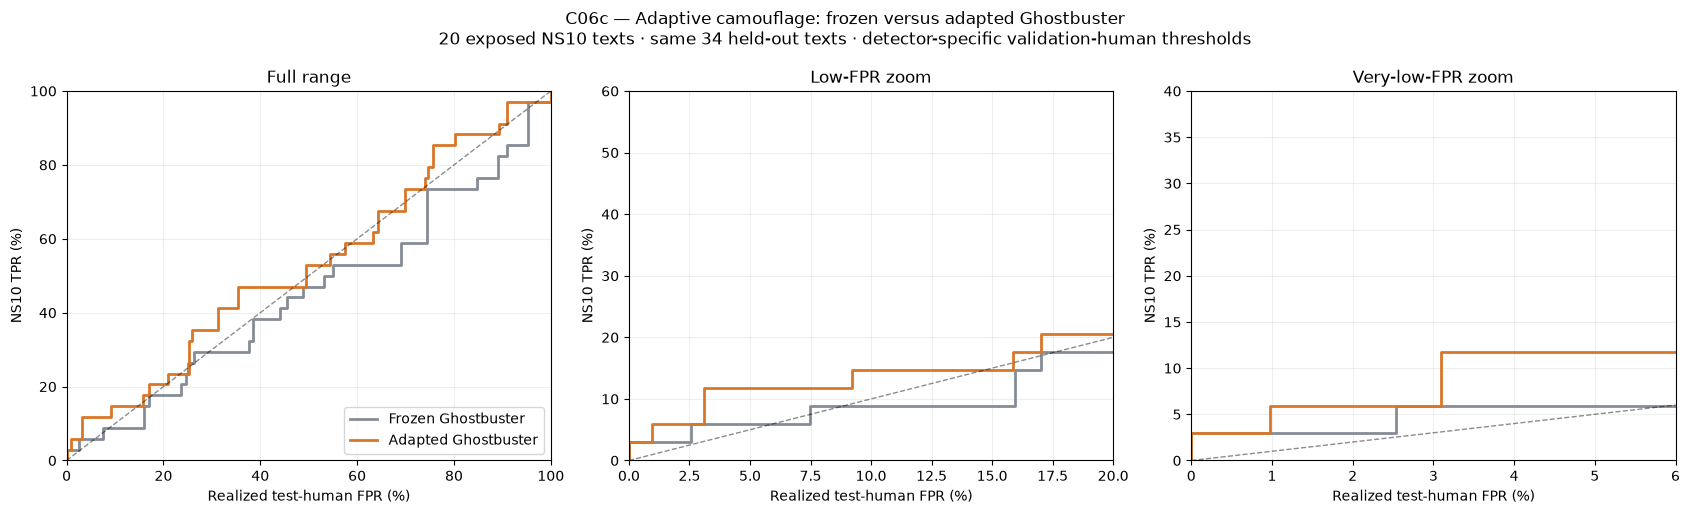

,detector,target_validation_FPR,threshold,calibration_FPR,realized_test_FPR,TPR
0,Frozen,0.01,0.92422,0.00000,0.00000,0.00000
1,Frozen,0.05,0.57441,0.04484,0.07474,0.08824
2,Frozen,0.10,0.53913,0.09452,0.07474,0.08824
3,Frozen,0.20,0.44678,0.19021,0.15941,0.14706
4,Frozen,0.50,0.20597,0.49675,0.45595,0.44118
5,Frozen,1.00,-inf,1.00000,1.00000,1.00000
6,Adapted,0.01,0.87925,0.00000,0.00000,0.02941
7,Adapted,0.05,0.65124,0.03869,0.03509,0.11765
8,Adapted,0.10,0.51259,0.09425,0.12489,0.14706
9,Adapted,0.20,0.43253,0.19936,0.20951,0.23529


Saved split, adapted model, scores, summaries and PNG/PDF graphs: ../results/causal/C06c_NS10_adaptive_Ghostbuster_20_34_v1


In [6]:
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
for ax,(xlim,ylim,title) in zip(axs,[((0,100),(0,100),'Full range'),
        ((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
    for name,color in [('Frozen','#858C96'),('Adapted','#D97728')]:
        st=curves[name]
        # Plot every threshold directly, including vertical runs at tied FPRs.
        ax.step(100*st.test_FPR,100*st.TPR,where='post',lw=2,color=color,
                label=f'{name} Ghostbuster')
    hi=min(xlim[1],ylim[1]);ax.plot([0,hi],[0,hi],'--',color='black',alpha=.45,lw=1)
    ax.set(xlim=xlim,ylim=ylim,title=title,xlabel='Realized test-human FPR (%)',ylabel='NS10 TPR (%)')
    ax.grid(alpha=.2)
axs[0].legend(loc='lower right')
fig.suptitle('C06c — Adaptive camouflage: frozen versus adapted Ghostbuster\n'
    '20 exposed NS10 texts · same 34 held-out texts · detector-specific validation-human thresholds')
fig.tight_layout()
for folder in [OUT,ROOT/'figures']:
    folder.mkdir(parents=True,exist_ok=True)
    for ext in ['png','pdf']:
        fig.savefig(folder/f'C06c_NS10_adaptive_20_34_TPR_staircase.{ext}',dpi=300,bbox_inches='tight')
plt.show()

# Operating points selected using validation humans only.
ops=[]
for name, st in curves.items():
    for target in [.01,.05,.10,.20,.50,1.0]:
        r=st.loc[st.calibration_FPR <= target+1e-12].iloc[-1]
        ops.append(dict(detector=name,target_validation_FPR=target,
            threshold=r.threshold,calibration_FPR=r.calibration_FPR,
            realized_test_FPR=r.test_FPR,TPR=r.TPR))
operating_points=pd.DataFrame(ops)
save_csv(operating_points,OUT/'validation_selected_operating_points.csv')
display(operating_points.round(5))
assert all(sha(ROOT/p)==h for p,h in contract['inputs'].items()), 'An input changed during execution.'
print('Saved split, adapted model, scores, summaries and PNG/PDF graphs:', OUT)


## Interpretation

Compare adapted versus frozen **on these same 34 cases**, using realized test-human FPR on the x-axis. Increased adapted AUROC/TPR indicates recovery of detection after exposure to 20 NS10 examples. Similar performance indicates limited recovery under this specific fixed-feature adaptation protocol. One random split is not an estimate of variability across exposure sets. No held-out NS10 example enters fitting or calibration. Human prose is never supplied to the rewrite pipeline.

The saved original detector remains untouched. The original RAID training set includes both labels; the 20 exposed NS10 examples are additional positives, not a one-class training set. Refitting repeats the original calibrated-classifier procedure on this augmented set. Symbolic search and normalization remain frozen to isolate adaptation of the classifier.